In [1]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

train_dataset = datasets.OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    transform=transform,
    download=True,
)

test_dataset = datasets.OxfordIIITPet(
    root="./data",
    split="test",
    target_types="category",
    transform=transform,
    download=True,
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [2]:
images, labels = next(iter(train_loader))

{tensor(0), tensor(36), tensor(26), tensor(11), tensor(23), tensor(1), tensor(28), tensor(14), tensor(22), tensor(18), tensor(7), tensor(16), tensor(4), tensor(1), tensor(23), tensor(5), tensor(27), tensor(33), tensor(28), tensor(32), tensor(9), tensor(4), tensor(30), tensor(0), tensor(5), tensor(3), tensor(6), tensor(20), tensor(21), tensor(27), tensor(21), tensor(23)}
torch.Size([3, 224, 224])
train len : 115


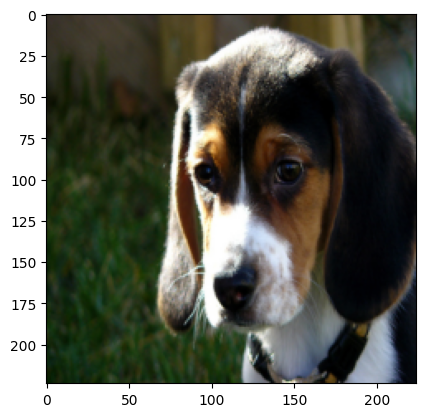

In [3]:
import matplotlib.pyplot as plt

print(set(labels))
print(images[0].shape)
image = images[0].permute(1,2,0)
plt.imshow(image)
len(test_dataset.classes)

print(f'train len : {len(train_loader)}')

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

class Net(nn.Module):
    def __init__(self):

        super().__init__()

        # strided encoder
        self.conv0 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1)
        self.conv1 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=2, padding=1)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=2, padding=1)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=2, padding=1)
        self.conv4 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=2, padding=1)
        self.global_pool = nn.AvgPool2d(kernel_size=14)

        # classifier head
        self.fc = nn.Linear(256, 37)

    def forward(self, x):
        x = F.relu(self.conv0(x))
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

In [7]:
from torchinfo import summary
model = Net()
print(summary(model))

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
model.train()
epochs = 5
losses = []

for epoch in range(epochs):
    for imgs, labels in train_loader:
        pred = model(imgs)
        loss = criterion(pred, labels)
        
        losses.append(loss)
        loss.backward()
        optimizer.step()
    print(f'loss after epoch {epoch} is {loss}')
    losses.append(loss)


Layer (type:depth-idx)                   Param #
Net                                      --
├─Conv2d: 1-1                            448
├─Conv2d: 1-2                            4,640
├─Conv2d: 1-3                            18,496
├─Conv2d: 1-4                            73,856
├─Conv2d: 1-5                            295,168
├─AvgPool2d: 1-6                         --
├─Linear: 1-7                            9,509
Total params: 402,117
Trainable params: 402,117
Non-trainable params: 0
loss after epoch 0 is 3.6085455417633057
loss after epoch 1 is 3.6446542739868164
loss after epoch 2 is 3.6165952682495117
loss after epoch 3 is 3.611238718032837
loss after epoch 4 is 3.6288676261901855
